In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv("SP1.csv")

In [3]:
data.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
0,SP1,12/08/2022,20:00,Osasuna,Sevilla,2,1,H,1,1,...,1.52,0.25,1.73,2.08,1.76,2.20,1.88,2.23,1.79,2.09
1,SP1,13/08/2022,16:00,Celta,Espanol,2,2,D,1,0,...,1.70,-0.75,2.00,1.90,2.02,1.91,2.06,1.93,2.01,1.86
2,SP1,13/08/2022,18:00,Valladolid,Villarreal,0,3,A,0,0,...,1.79,0.25,2.02,1.88,2.02,1.91,2.03,1.91,1.98,1.88
3,SP1,13/08/2022,20:00,Barcelona,Vallecano,0,0,D,0,0,...,2.61,-1.75,1.82,2.08,1.83,2.08,1.86,2.14,1.82,2.06
4,SP1,14/08/2022,16:30,Cadiz,Sociedad,0,1,A,0,1,...,1.50,0.25,2.05,1.85,2.06,1.87,2.08,1.92,2.00,1.86


In [4]:
data.nunique()

Div           1
Date        139
Time         12
HomeTeam     20
AwayTeam     20
           ... 
PCAHA        46
MaxCAHH      45
MaxCAHA      47
AvgCAHH      43
AvgCAHA      42
Length: 105, dtype: int64

In [5]:
Home_teams = data['HomeTeam']
Home_teams.duplicated().sum()

360

In [6]:
Away_teams = data['AwayTeam']

In [7]:
Home_teams_total = Home_teams.drop_duplicates()

In [8]:
Away_teams_total = Home_teams_total
Away_teams_total

0         Osasuna
1           Celta
2      Valladolid
3       Barcelona
4           Cadiz
5        Valencia
6         Almeria
7      Ath Bilbao
8          Getafe
9           Betis
10        Espanol
11        Sevilla
13       Mallorca
16     Ath Madrid
17       Sociedad
18          Elche
19         Girona
23      Vallecano
32    Real Madrid
37     Villarreal
Name: HomeTeam, dtype: object

In [9]:
Home_team_goals = data['HTHG']
Away_team_goals = data['HTAG']

In [10]:
half_time_data = pd.DataFrame({
    "HomeTeam": Home_teams,
    "AwayTeam": Away_teams,
    "HTHG": Home_team_goals,
    "HTAG": Away_team_goals
})

In [11]:
half_time_data.head()

,HomeTeam,AwayTeam,HTHG,HTAG
0,Osasuna,Sevilla,1,1
1,Celta,Espanol,1,0
2,Valladolid,Villarreal,0,0
3,Barcelona,Vallecano,0,0
4,Cadiz,Sociedad,0,1


In [12]:
home_team_goals = half_time_data.groupby("HomeTeam")['HTHG'].sum()
home_team_goals

HomeTeam
Almeria        16
Ath Bilbao     13
Ath Madrid     16
Barcelona      23
Betis          15
Cadiz           9
Celta          12
Elche          10
Espanol         7
Getafe         11
Girona         16
Mallorca        6
Osasuna         8
Real Madrid    22
Sevilla        13
Sociedad       15
Valencia       11
Valladolid      9
Vallecano      13
Villarreal     12
Name: HTHG, dtype: int64

In [13]:
away_team_goals = half_time_data.groupby("AwayTeam")['HTAG'].sum()
away_team_goals

AwayTeam
Almeria        10
Ath Bilbao     12
Ath Madrid     12
Barcelona      11
Betis           9
Cadiz           3
Celta           8
Elche           5
Espanol         8
Getafe          4
Girona         10
Mallorca        6
Osasuna         8
Real Madrid    13
Sevilla        10
Sociedad       13
Valencia        7
Valladolid      8
Vallecano       5
Villarreal      6
Name: HTAG, dtype: int64

In [14]:
teams = []
teams = Home_teams_total
teams.sort_values(inplace=True)
teams

6         Almeria
7      Ath Bilbao
16     Ath Madrid
3       Barcelona
9           Betis
4           Cadiz
1           Celta
18          Elche
10        Espanol
8          Getafe
19         Girona
13       Mallorca
0         Osasuna
32    Real Madrid
11        Sevilla
17       Sociedad
5        Valencia
2      Valladolid
23      Vallecano
37     Villarreal
Name: HomeTeam, dtype: object

In [15]:
x = np.arange(len(teams))
x

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [16]:
bar_width = 0.3

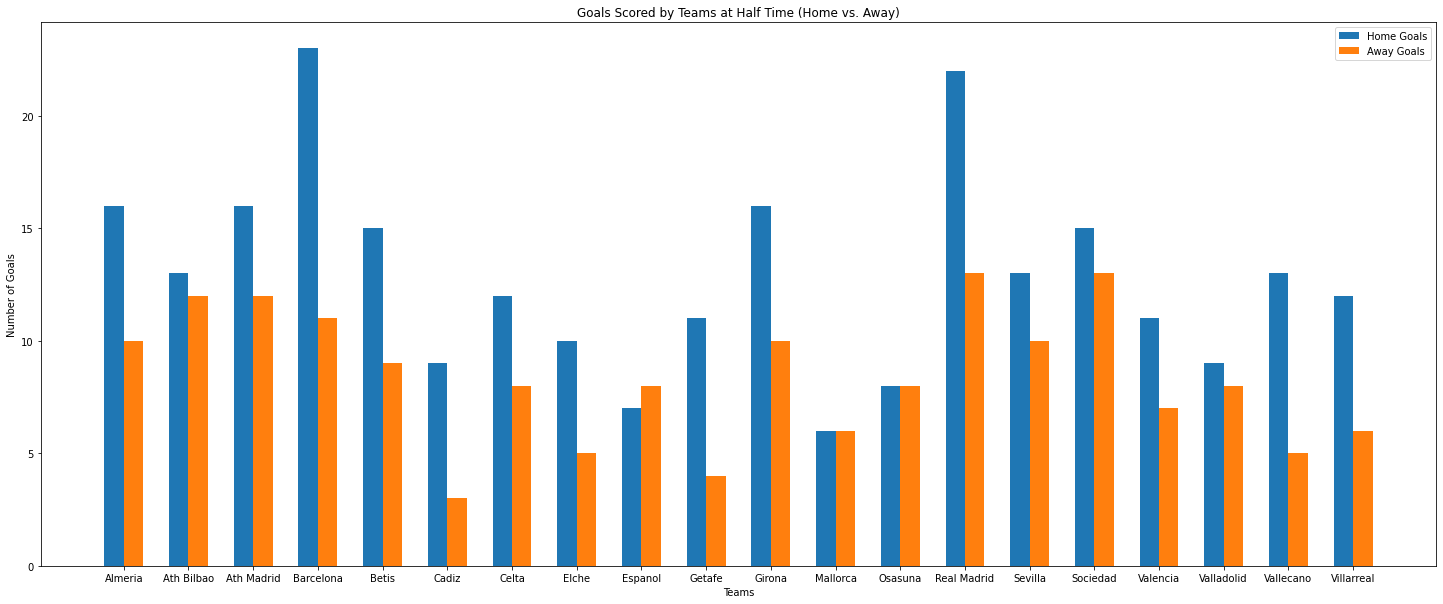

In [17]:
plt.figure(figsize=(25,10))
plt.bar(x - bar_width/2, home_team_goals, width=bar_width, label='Home Goals')
plt.bar(x + bar_width/2, away_team_goals, width=bar_width, label='Away Goals')
plt.xlabel('Teams')
plt.ylabel('Number of Goals')
plt.title('Goals Scored by Teams at Half Time (Home vs. Away)')
plt.xticks(x, teams)
plt.legend()